## Task 1: Descriptive Statistics & Exploratory Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100

df = pd.read_csv('hour.csv', parse_dates=['dteday'])
print(df.shape)
df.head()

(17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [2]:
# Basic info: types, missing values
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-null  int64

In [3]:
# Any missing values or duplicate rows search.
print("Missing values per column:\n", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Check for missing HOURS (gaps in the hourly time series)
full_range = pd.date_range(df['dteday'].min(), df['dteday'].max() + pd.Timedelta(hours=23), freq='h')
print(f"Expected hourly timestamps: {len(full_range)}")
print(f"Actual rows: {len(df)}")
print(f"Missing hours: {len(full_range) - len(df)}")

Missing values per column:
 0
Duplicate rows: 0
Expected hourly timestamps: 17544
Actual rows: 17379
Missing hours: 165


In [4]:
df.describe()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2012-01-02 04:08:34.552045,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
min,1.0000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2011-07-04 00:00:00,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,2012-01-02 00:00:00,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,2012-07-02 00:00:00,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000
std,5017.0295,NaN,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599


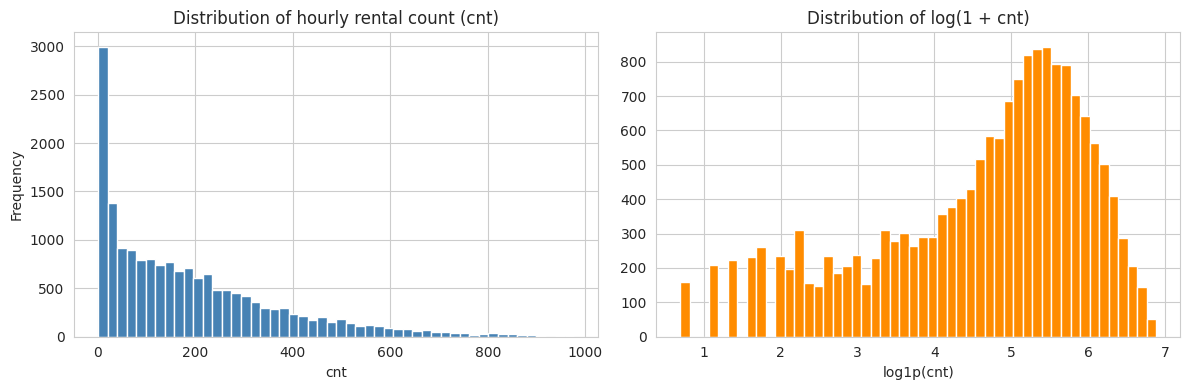

cnt skewness: 1.28
log1p(cnt) skewness: -0.82


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['cnt'], bins=50, color='steelblue', edgecolor='white')
axes[0].set_title('Distribution of hourly rental count (cnt)')
axes[0].set_xlabel('cnt')
axes[0].set_ylabel('Frequency')

axes[1].hist(np.log1p(df['cnt']), bins=50, color='darkorange', edgecolor='white')
axes[1].set_title('Distribution of log(1 + cnt)')
axes[1].set_xlabel('log1p(cnt)')

plt.tight_layout()
plt.show()

print("cnt skewness:", df['cnt'].skew().round(2))
print("log1p(cnt) skewness:", np.log1p(df['cnt']).skew().round(2))

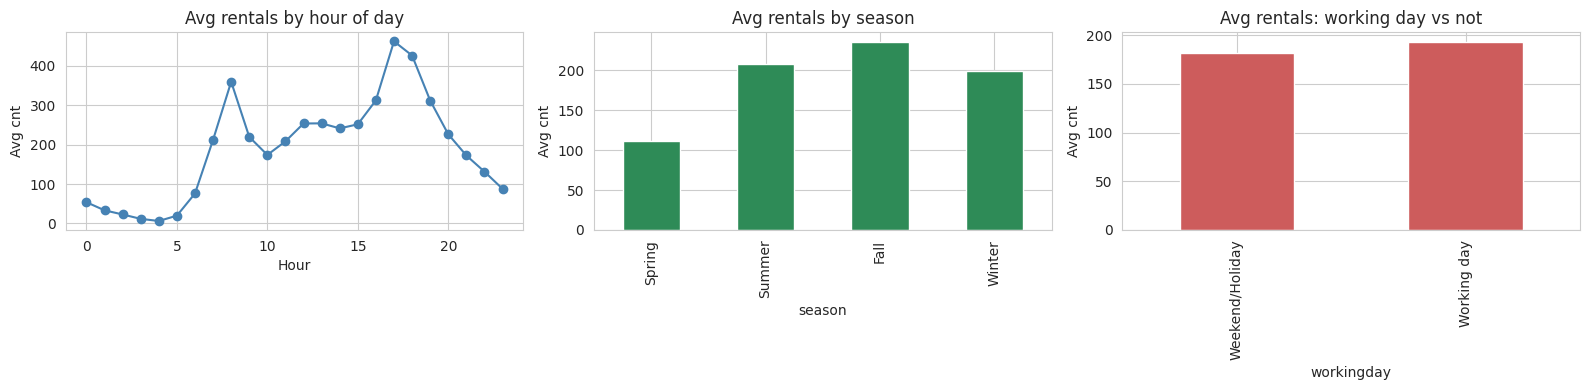

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Average rentals by hour of day
df.groupby('hr')['cnt'].mean().plot(ax=axes[0], marker='o', color='steelblue')
axes[0].set_title('Avg rentals by hour of day')
axes[0].set_xlabel('Hour'); axes[0].set_ylabel('Avg cnt')

# Average rentals by season
season_labels = {1:'Spring', 2:'Summer', 3:'Fall', 4:'Winter'}
df.groupby('season')['cnt'].mean().rename(index=season_labels).plot(kind='bar', ax=axes[1], color='seagreen')
axes[1].set_title('Avg rentals by season')
axes[1].set_ylabel('Avg cnt')

# Working day vs weekend/holiday
df.groupby('workingday')['cnt'].mean().rename(index={0:'Weekend/Holiday', 1:'Working day'}).plot(kind='bar', ax=axes[2], color='indianred')
axes[2].set_title('Avg rentals: working day vs not')
axes[2].set_ylabel('Avg cnt')

plt.tight_layout()
plt.show()

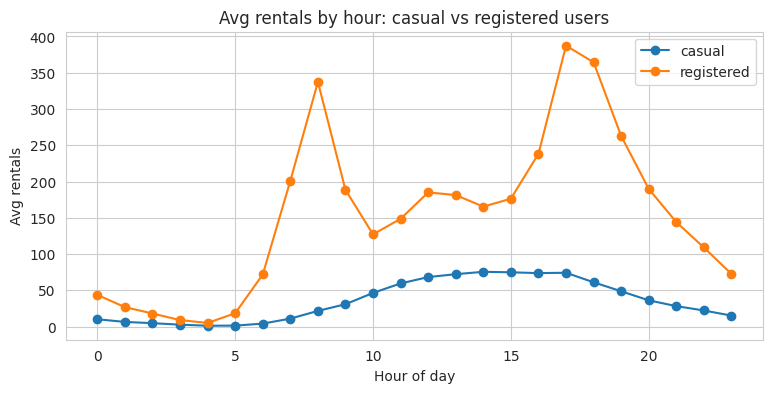

Share of total rentals -- casual: 18.8 %
Share of total rentals -- registered: 81.2 %


,casual,registered
workingday,,
Weekend/Holiday,57.441422,123.963910
Working day,25.561315,167.646439


In [7]:
fig, ax = plt.subplots(figsize=(9, 4))

hourly = df.groupby('hr')[['casual', 'registered']].mean()
hourly.plot(ax=ax, marker='o')
ax.set_title('Avg rentals by hour: casual vs registered users')
ax.set_xlabel('Hour of day'); ax.set_ylabel('Avg rentals')
plt.show()

print("Share of total rentals -- casual:", round(df['casual'].sum() / df['cnt'].sum() * 100, 1), "%")
print("Share of total rentals -- registered:", round(df['registered'].sum() / df['cnt'].sum() * 100, 1), "%")

# Casual vs registered on working days vs weekends
comparison = df.groupby('workingday')[['casual', 'registered']].mean().rename(
    index={0: 'Weekend/Holiday', 1: 'Working day'})
comparison

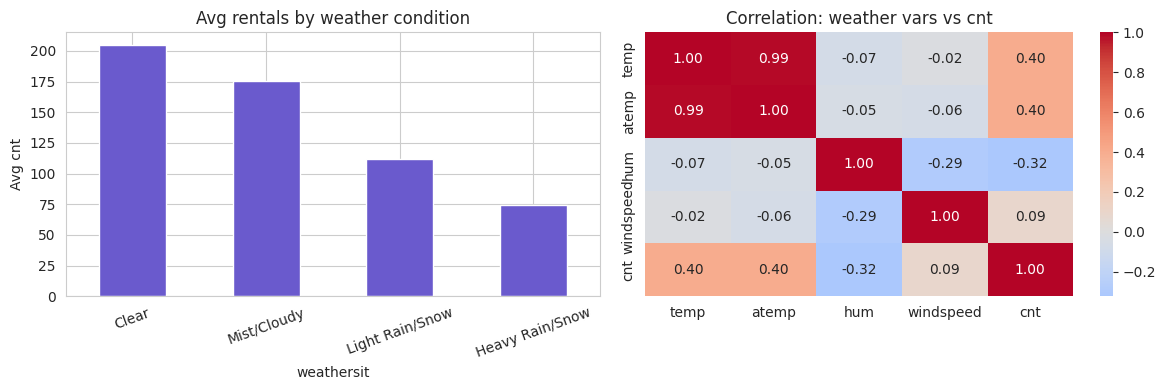

In [8]:
weather_labels = {1: 'Clear', 2: 'Mist/Cloudy', 3: 'Light Rain/Snow', 4: 'Heavy Rain/Snow'}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df.groupby('weathersit')['cnt'].mean().rename(index=weather_labels).plot(kind='bar', ax=axes[0], color='slateblue')
axes[0].set_title('Avg rentals by weather condition')
axes[0].set_ylabel('Avg cnt')
axes[0].tick_params(axis='x', rotation=20)

corr_cols = ['temp', 'atemp', 'hum', 'windspeed', 'cnt']
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('Correlation: weather vars vs cnt')

plt.tight_layout()
plt.show()

## Task 2: Statistical & Regression Analysis

In [9]:
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Treat season and weathersit as categorical 
reg_df = df.copy()
reg_df['season'] = reg_df['season'].astype('category')
reg_df['weathersit'] = reg_df['weathersit'].astype('category')

formula = "cnt ~ C(season) + yr + hr + holiday + weekday + workingday + C(weathersit) + temp + atemp + hum + windspeed"
ols_model = smf.ols(formula=formula, data=reg_df).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.399
Model:                            OLS   Adj. R-squared:                  0.398
Method:                 Least Squares   F-statistic:                     767.6
Date:                Tue, 15 Sep 2026   Prob (F-statistic):               0.00
Time:                        23:51:19   Log-Likelihood:            -1.1062e+05
No. Observations:               17379   AIC:                         2.213e+05
Df Residuals:                   17363   BIC:                         2.214e+05
Df Model:                          15                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept            -30.8107      7

In [10]:
X_vif = reg_df[['temp', 'atemp', 'hum', 'windspeed', 'yr', 'hr', 'holiday', 'weekday', 'workingday']].copy()
X_vif = sm.add_constant(X_vif)

vif_data = pd.DataFrame({
    'feature': X_vif.columns,
    'VIF': [variance_inflation_factor(X_vif.values, i) for i in range(X_vif.shape[1])]
})
vif_data

,feature,VIF
0,const,1.000000
1,temp,43.676751
2,atemp,43.819348
3,hum,1.181367
4,windspeed,1.164015
5,yr,1.010468
6,hr,1.107083
7,holiday,1.079486
8,weekday,1.014477
9,workingday,1.071360


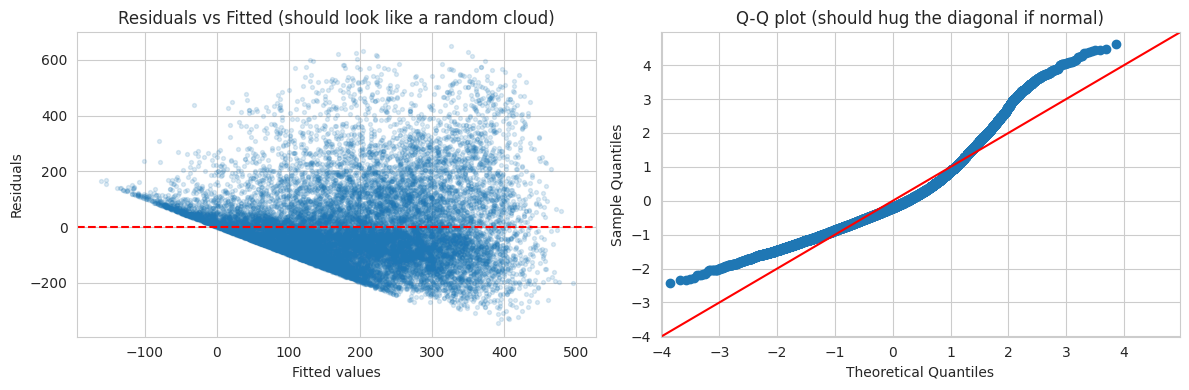

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

residuals = ols_model.resid
fitted = ols_model.fittedvalues

axes[0].scatter(fitted, residuals, alpha=0.15, s=8)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Fitted values'); axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs Fitted (should look like a random cloud)')

sm.qqplot(residuals, line='45', fit=True, ax=axes[1])
axes[1].set_title('Q-Q plot (should hug the diagonal if normal)')

plt.tight_layout()
plt.show()

In [12]:
print("Mean of cnt:", reg_df['cnt'].mean().round(1))
print("Variance of cnt:", reg_df['cnt'].var().round(1))
print("Variance / Mean ratio:", (reg_df['cnt'].var() / reg_df['cnt'].mean()).round(1))

Mean of cnt: 189.5
Variance of cnt: 32901.5
Variance / Mean ratio: 173.7


In [13]:
# Drop atemp (multicollinear with temp) going forward, per the VIF check earlier
formula_count = "cnt ~ C(season) + yr + hr + holiday + weekday + workingday + C(weathersit) + temp + hum + windspeed"

poisson_model = smf.glm(formula=formula_count, data=reg_df, family=sm.families.Poisson()).fit()
print("Poisson deviance / df_resid (should be ~1 if not overdispersed):",
      round(poisson_model.deviance / poisson_model.df_resid, 2))

# smf.negativebinomial estimates the dispersion parameter (alpha) by maximum likelihood,
# rather than fixing it at an arbitrary default -- important since alpha directly controls
# how much extra variance the model accounts for beyond plain Poisson.
nb_model = smf.negativebinomial(formula=formula_count, data=reg_df).fit(method='bfgs', maxiter=200, disp=0)
print("\nEstimated NB dispersion parameter (alpha):", round(nb_model.params['alpha'], 4))
print("\nNegative Binomial model fit -- AIC comparison:")
print("Poisson AIC:", round(poisson_model.aic, 1))
print("Negative Binomial AIC:", round(nb_model.aic, 1), "(lower is better)")

Poisson deviance / df_resid (should be ~1 if not overdispersed): 94.73



Estimated NB dispersion parameter (alpha): 0.7995

Negative Binomial model fit -- AIC comparison:
Poisson AIC: 1755739.9
Negative Binomial AIC: 208429.2 (lower is better)


In [14]:
print(nb_model.summary())

                     NegativeBinomial Regression Results                      
Dep. Variable:                    cnt   No. Observations:                17379
Model:               NegativeBinomial   Df Residuals:                    17364
Method:                           MLE   Df Model:                           14
Date:                Tue, 15 Sep 2026   Pseudo R-squ.:                 0.03874
Time:                        23:51:20   Log-Likelihood:            -1.0420e+05
converged:                       True   LL-Null:                   -1.0840e+05
Covariance Type:            nonrobust   LLR p-value:                     0.000
                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              3.2045      0.047     68.306      0.000       3.113       3.296
C(season)[T.2]         0.2117      0.024      8.651      0.000       0.164       0.260
C(season)[T.3]      

In [15]:
import numpy as np

coefs = nb_model.params.drop('alpha')
effects = np.exp(coefs)
effects_pct = (effects - 1) * 100

effects_table = pd.DataFrame({
    'coef (log scale)': coefs.round(4),
    'multiplicative effect': effects.round(3),
    '% change in expected rentals': effects_pct.round(1)
}).sort_values('% change in expected rentals', ascending=False)

effects_table

,coef (log scale),multiplicative effect,% change in expected rentals
Intercept,3.2045,24.643,2364.3
temp,1.8535,6.382,538.2
yr,0.4746,1.607,60.7
C(season)[T.4],0.4617,1.587,58.7
C(season)[T.2],0.2117,1.236,23.6
windspeed,0.1509,1.163,16.3
C(weathersit)[T.2],0.1015,1.107,10.7
C(season)[T.3],0.0840,1.088,8.8
workingday,0.0822,1.086,8.6
hr,0.0730,1.076,7.6


## Task 3: Demand Forecasting & Predictive Modeling

In [16]:
# Sort chronologically first, critical for any shift/rolling operation to be correct
ts_df = df.sort_values(['dteday', 'hr']).reset_index(drop=True).copy()

# Build a proper datetime column combining date + hour
ts_df['datetime'] = ts_df['dteday'] + pd.to_timedelta(ts_df['hr'], unit='h')

# Lag features: cnt from 1 hour ago, 24 hours ago (same hour yesterday), 168 hours ago (same hour last week)
ts_df['lag_1'] = ts_df['cnt'].shift(1)
ts_df['lag_24'] = ts_df['cnt'].shift(24)
ts_df['lag_168'] = ts_df['cnt'].shift(168)

# Rolling features: average demand over the past 24 hours and past 7 days,
# computed causally (each row only "sees" hours strictly before it)
ts_df['roll_mean_24'] = ts_df['cnt'].shift(1).rolling(window=24, min_periods=24).mean()
ts_df['roll_mean_168'] = ts_df['cnt'].shift(1).rolling(window=168, min_periods=168).mean()

ts_df[['datetime', 'cnt', 'lag_1', 'lag_24', 'lag_168', 'roll_mean_24', 'roll_mean_168']].head(10)

,datetime,cnt,lag_1,lag_24,lag_168,roll_mean_24,roll_mean_168
0,2011-01-01 00:00:00,16,NaN,NaN,NaN,NaN,NaN
1,2011-01-01 01:00:00,40,16.0,NaN,NaN,NaN,NaN
2,2011-01-01 02:00:00,32,40.0,NaN,NaN,NaN,NaN
3,2011-01-01 03:00:00,13,32.0,NaN,NaN,NaN,NaN
4,2011-01-01 04:00:00,1,13.0,NaN,NaN,NaN,NaN
5,2011-01-01 05:00:00,1,1.0,NaN,NaN,NaN,NaN
6,2011-01-01 06:00:00,2,1.0,NaN,NaN,NaN,NaN
7,2011-01-01 07:00:00,3,2.0,NaN,NaN,NaN,NaN
8,2011-01-01 08:00:00,8,3.0,NaN,NaN,NaN,NaN
9,2011-01-01 09:00:00,14,8.0,NaN,NaN,NaN,NaN


In [17]:
# Reindex onto a complete hourly timeline to expose the 165 missing hours as real gaps
model_features = ['lag_1', 'lag_24', 'lag_168', 'roll_mean_24', 'roll_mean_168',
                   'hr_sin', 'hr_cos', 'month_sin', 'month_cos', 'weekday',
                   'holiday', 'workingday', 'temp', 'hum', 'windspeed', 'weathersit', 'season']
full_index = pd.date_range(ts_df['datetime'].min(), ts_df['datetime'].max(), freq='h')
ts_df = ts_df.set_index('datetime').reindex(full_index)
ts_df.index.name = 'datetime'
ts_df = ts_df.reset_index()

print("Rows after reindexing (should be 17544, matching our earlier full_range calc):", len(ts_df))
print("Rows with NaN cnt (the 165 originally-missing hours, now explicit):", ts_df['cnt'].isna().sum())

# Forward-fill short gaps (<=6h) using only PAST known values -- leakage-safe.
# This must happen BEFORE lag/rolling features are computed, so those features
# are built on the corrected series, not the raw one with gaps still in it.
ts_df['cnt'] = ts_df['cnt'].ffill(limit=6)
ts_df[['season', 'weathersit', 'holiday', 'workingday', 'temp', 'hum', 'windspeed']] = \
    ts_df[['season', 'weathersit', 'holiday', 'workingday', 'temp', 'hum', 'windspeed']].ffill(limit=6)

print("Remaining NaN in cnt after forward-fill:", ts_df['cnt'].isna().sum())

# Now recompute lag/rolling features on this gap-filled timeline. 
ts_df['lag_1'] = ts_df['cnt'].shift(1)
ts_df['lag_24'] = ts_df['cnt'].shift(24)
ts_df['lag_168'] = ts_df['cnt'].shift(168)
ts_df['roll_mean_24'] = ts_df['cnt'].shift(1).rolling(window=24, min_periods=24).mean()
ts_df['roll_mean_168'] = ts_df['cnt'].shift(1).rolling(window=168, min_periods=168).mean()

# Cyclical encoding for hour and month: a plain number (e.g. hr=23) doesn't tell the model
# that hour 23 is right next to hour 0 -- sine/cosine encoding fixes that
ts_df['hr'] = ts_df['datetime'].dt.hour
ts_df['hr_sin'] = np.sin(2 * np.pi * ts_df['hr'] / 24)
ts_df['hr_cos'] = np.cos(2 * np.pi * ts_df['hr'] / 24)
ts_df['month'] = ts_df['datetime'].dt.month
ts_df['month_sin'] = np.sin(2 * np.pi * ts_df['month'] / 12)
ts_df['month_cos'] = np.cos(2 * np.pi * ts_df['month'] / 12)

# Re-derive day/weekday/date fields 
ts_df['dteday'] = ts_df['datetime'].dt.date
ts_df['day_of_month'] = ts_df['datetime'].dt.day
ts_df['weekday'] = ts_df['datetime'].dt.weekday

ts_df[['datetime', 'cnt', 'lag_1', 'lag_24', 'hr_sin', 'hr_cos']].iloc[160:175]

Rows after reindexing (should be 17544, matching our earlier full_range calc): 17544
Rows with NaN cnt (the 165 originally-missing hours, now explicit): 165
Remaining NaN in cnt after forward-fill: 59


,datetime,cnt,lag_1,lag_24,hr_sin,hr_cos
160,2011-01-07 16:00:00,87.0,72.0,86.0,-0.866025,-5.000000e-01
161,2011-01-07 17:00:00,187.0,87.0,172.0,-0.965926,-2.588190e-01
162,2011-01-07 18:00:00,123.0,187.0,163.0,-1.000000,-1.836970e-16
163,2011-01-07 19:00:00,95.0,123.0,112.0,-0.965926,2.588190e-01
164,2011-01-07 20:00:00,51.0,95.0,69.0,-0.866025,5.000000e-01
165,2011-01-07 21:00:00,39.0,51.0,48.0,-0.707107,7.071068e-01
166,2011-01-07 22:00:00,36.0,39.0,52.0,-0.500000,8.660254e-01
167,2011-01-07 23:00:00,15.0,36.0,23.0,-0.258819,9.659258e-01
168,2011-01-08 00:00:00,25.0,15.0,17.0,0.000000,1.000000e+00
169,2011-01-08 01:00:00,16.0,25.0,7.0,0.258819,9.659258e-01


In [18]:
# Full feature list used across ALL models (XGBoost, Linear Regression baseline, etc.)
# defined here so the NaN check below covers every column any model will actually use.
model_features = ['lag_1', 'lag_24', 'lag_168', 'roll_mean_24', 'roll_mean_168',
                   'hr_sin', 'hr_cos', 'month_sin', 'month_cos', 'weekday',
                   'holiday', 'workingday', 'temp', 'hum', 'windspeed', 'weathersit', 'season']

# Rows with NaN in any feature we actually model with can't be used for training/prediction 
# this includes the first 168 hours (no full week of history yet), any row whose lag/rolling
# window touches an originally-missing hour beyond the 6-hour fill limit, and any row with an
# unfilled weather/calendar value. Also drop rows where cnt itself is NaN.
model_df = ts_df.dropna(subset=model_features + ['cnt']).reset_index(drop=True)
print("Rows remaining after dropping NaNs:", len(model_df))

# THE SPECIFIED SPLIT: day_of_month 1-20 = train, 21-end = test
train_df = model_df[model_df['day_of_month'] <= 20].copy()
test_df = model_df[model_df['day_of_month'] > 20].copy()

print("Train rows:", len(train_df), " Test rows:", len(test_df))
print("Train date range:", train_df['datetime'].min(), "to", train_df['datetime'].max())
print("Test date range:", test_df['datetime'].min(), "to", test_df['datetime'].max())

Rows remaining after dropping NaNs: 16645
Train rows: 11010  Test rows: 5635
Train date range: 2011-01-08 00:00:00 to 2012-12-20 23:00:00
Test date range: 2011-01-25 12:00:00 to 2012-12-31 23:00:00


In [19]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Full feature set: our engineered time-series features + the weather/calendar features from Part 1/2
model_features = ['lag_1', 'lag_24', 'lag_168', 'roll_mean_24', 'roll_mean_168',
                   'hr_sin', 'hr_cos', 'month_sin', 'month_cos', 'weekday',
                   'holiday', 'workingday', 'temp', 'hum', 'windspeed', 'weathersit', 'season']

X_train, y_train = train_df[model_features], train_df['cnt']
X_test, y_test = test_df[model_features], test_df['cnt']

xgb_model = XGBRegressor(
    n_estimators=300, max_depth=6, learning_rate=0.05,
    subsample=0.8, colsample_bytree=0.8, random_state=42
)
xgb_model.fit(X_train, y_train)

preds = xgb_model.predict(X_test)
preds = np.clip(preds, 0, None)  # rentals can't be negative

mae = mean_absolute_error(y_test, preds)
rmse = np.sqrt(mean_squared_error(y_test, preds))
r2 = r2_score(y_test, preds)

print(f"MAE:  {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R²:   {r2:.4f}")

MAE:  22.92
RMSE: 36.77
R²:   0.9594


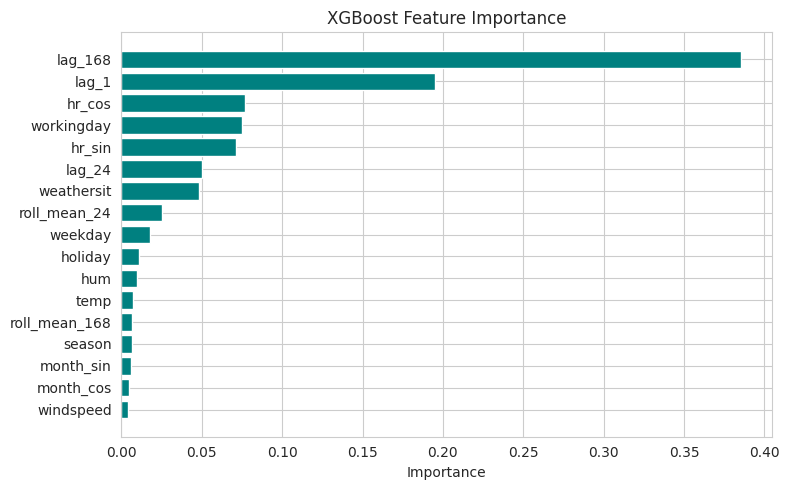

,feature,importance
2,lag_168,0.385646
0,lag_1,0.195255
6,hr_cos,0.077052
11,workingday,0.074896
5,hr_sin,0.071332
1,lag_24,0.049963
15,weathersit,0.048489
3,roll_mean_24,0.025201
9,weekday,0.017787
10,holiday,0.010643


In [20]:
importance = pd.DataFrame({
    'feature': model_features,
    'importance': xgb_model.feature_importances_
}).sort_values('importance', ascending=False)

plt.figure(figsize=(8, 5))
plt.barh(importance['feature'], importance['importance'], color='teal')
plt.gca().invert_yaxis()
plt.title('XGBoost Feature Importance')
plt.xlabel('Importance')
plt.tight_layout()
plt.show()

importance

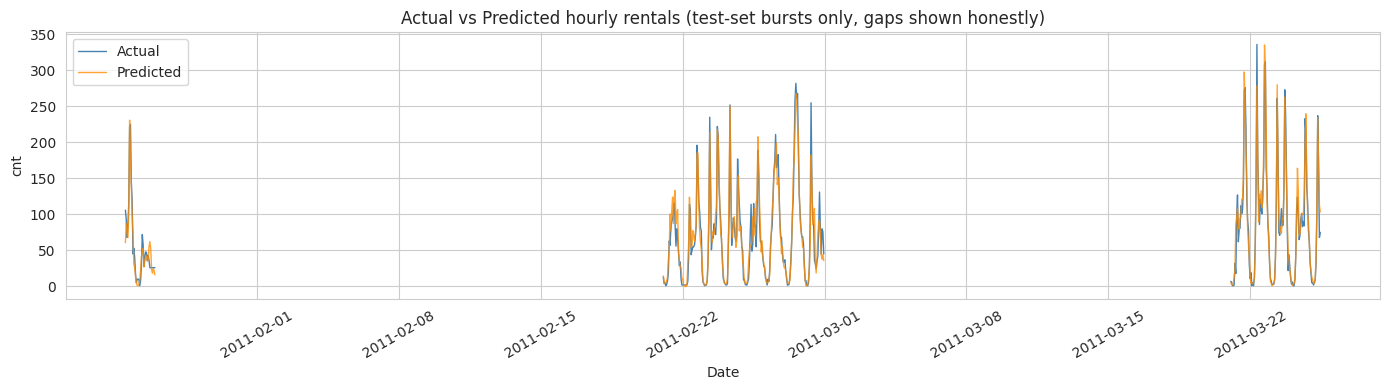

In [21]:
plt.figure(figsize=(14, 4))

# Insert a NaN wherever there's a real time gap (>1 hour) between consecutive test rows,
# so matplotlib breaks the line instead of connecting across the gap
sample = test_df.iloc[:14*24].copy().reset_index(drop=True)
sample_preds = np.clip(xgb_model.predict(sample[model_features]), 0, None)
sample['pred'] = sample_preds

time_diffs = sample['datetime'].diff().dt.total_seconds() / 3600
gap_mask = time_diffs > 1
sample.loc[gap_mask, ['cnt', 'pred']] = np.nan  # breaks the line at real gaps

plt.plot(sample['datetime'], sample['cnt'], label='Actual', color='steelblue', linewidth=1)
plt.plot(sample['datetime'], sample['pred'], label='Predicted', color='darkorange', linewidth=1, alpha=0.8)
plt.title('Actual vs Predicted hourly rentals (test-set bursts only, gaps shown honestly)')
plt.xlabel('Date'); plt.ylabel('cnt')
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [22]:
from sklearn.linear_model import LinearRegression

# Defensive check: confirm X_train/X_test are actually clean before modeling,
# rather than assuming an earlier cell's dropna is still in effect
print("NaN count in X_train:", X_train.isna().sum().sum())
print("NaN count in X_test:", X_test.isna().sum().sum())

train_mask = X_train.notna().all(axis=1)
test_mask = X_test.notna().all(axis=1)
X_train_c, y_train_c = X_train[train_mask], y_train[train_mask]
X_test_c, y_test_c = X_test[test_mask], y_test[test_mask]
print(f"Dropped {(~train_mask).sum()} train rows and {(~test_mask).sum()} test rows with residual NaNs")

# Baseline 1: Naive persistence -- predict this hour using lag_168 (same hour, one week ago)
naive_preds = test_df.loc[test_mask, 'lag_168'].values
naive_mae = mean_absolute_error(y_test_c, naive_preds)
naive_rmse = np.sqrt(mean_squared_error(y_test_c, naive_preds))
naive_r2 = r2_score(y_test_c, naive_preds)

# Baseline 2: Linear Regression on the SAME features as XGBoost
lr_model = LinearRegression()
lr_model.fit(X_train_c, y_train_c)
lr_preds = np.clip(lr_model.predict(X_test_c), 0, None)
lr_mae = mean_absolute_error(y_test_c, lr_preds)
lr_rmse = np.sqrt(mean_squared_error(y_test_c, lr_preds))
lr_r2 = r2_score(y_test_c, lr_preds)

comparison_table = pd.DataFrame({
    'Model': ['Naive (last week, same hour)', 'Linear Regression', 'XGBoost'],
    'MAE': [naive_mae, lr_mae, mae],
    'RMSE': [naive_rmse, lr_rmse, rmse],
    'R2': [naive_r2, lr_r2, r2]
}).round(3)

comparison_table

NaN count in X_train: 0
NaN count in X_test: 0
Dropped 0 train rows and 0 test rows with residual NaNs


,Model,MAE,RMSE,R2
0,"Naive (last week, same hour)",59.058,101.949,0.688
1,Linear Regression,44.726,68.570,0.859
2,XGBoost,22.923,36.773,0.959


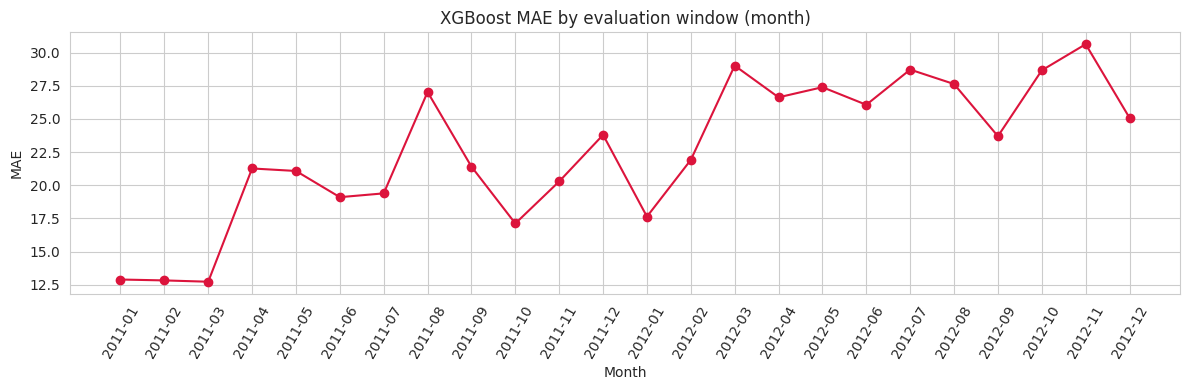

Best window MAE: 12.7 in 2011-03
Worst window MAE: 30.6 in 2012-11
Mean of per-window MAE: 22.6
Std of per-window MAE: 5.4


In [23]:
test_eval = test_df.loc[test_mask].copy()
test_eval['pred'] = np.clip(xgb_model.predict(X_test_c), 0, None)
test_eval['year_month'] = test_eval['datetime'].dt.to_period('M')

def window_metrics(g):
    return pd.Series({
        'MAE': mean_absolute_error(g['cnt'], g['pred']),
        'RMSE': np.sqrt(mean_squared_error(g['cnt'], g['pred'])),
        'R2': r2_score(g['cnt'], g['pred']),
        'n_hours': len(g)
    })

monthly_perf = test_eval.groupby('year_month').apply(window_metrics, include_groups=False)

plt.figure(figsize=(12, 4))
plt.plot(monthly_perf.index.astype(str), monthly_perf['MAE'], marker='o', color='crimson')
plt.title('XGBoost MAE by evaluation window (month)')
plt.xlabel('Month'); plt.ylabel('MAE')
plt.xticks(rotation=60)
plt.tight_layout()
plt.savefig('fig_monthly_performance.png', dpi=150)
plt.show()

print("Best window MAE:", monthly_perf['MAE'].min().round(1), "in", monthly_perf['MAE'].idxmin())
print("Worst window MAE:", monthly_perf['MAE'].max().round(1), "in", monthly_perf['MAE'].idxmax())
print("Mean of per-window MAE:", monthly_perf['MAE'].mean().round(1))
print("Std of per-window MAE:", monthly_perf['MAE'].std().round(1))